| Nama | NRP |
| :--- | :--- |
| Lyonel Oliver Dwiputra | 5025241145 |
| Kadek Andra Wikanjaya Putra | 5025241187 |
| A. Wildan Kevin Assyauqi | 5025241265 |
| Raziq Danish Safaraz | 5025241258 |

## Import Library

In [25]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

## Gambar Sebelum Enhanced

(np.float64(-0.5), np.float64(7710.5), np.float64(7830.5), np.float64(-0.5))

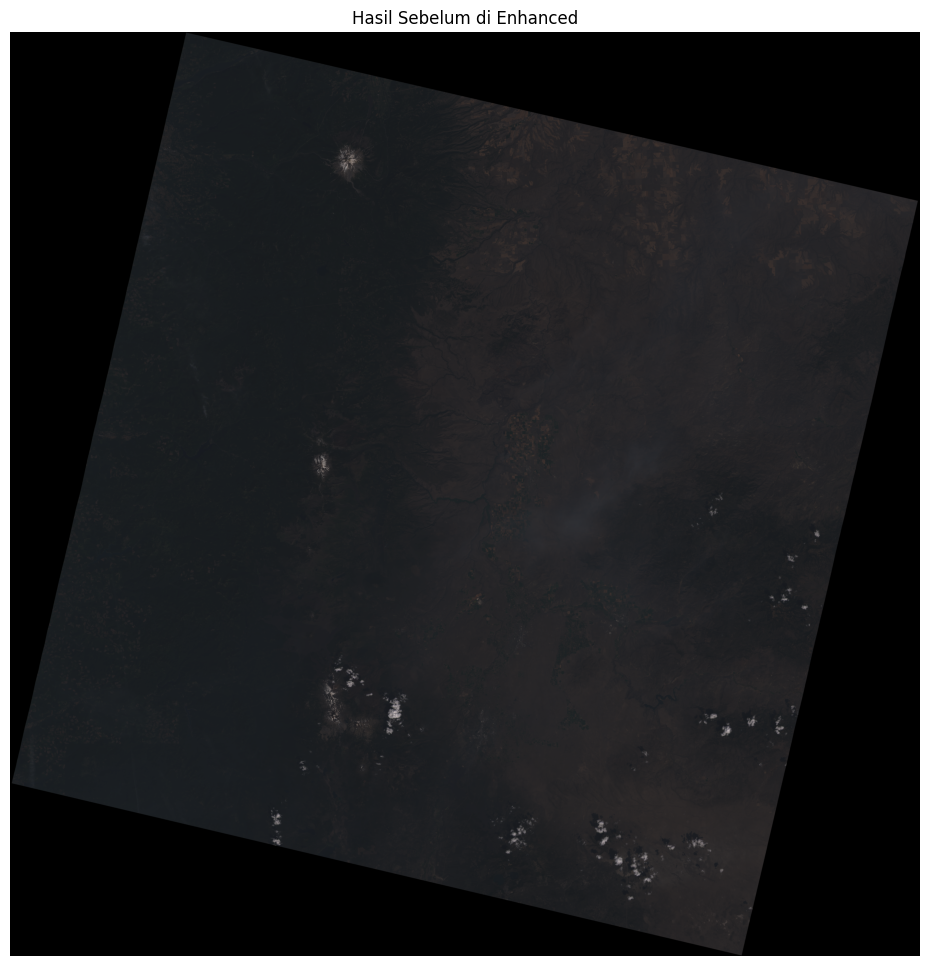

In [26]:
img = cv2.imread('/content/citra_input.png')


plt.figure(figsize=(12, 12))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Hasil Sebelum di Enhanced")
plt.axis('off')

## Enhancement Image

### Enhancement Image dengan 8-bit

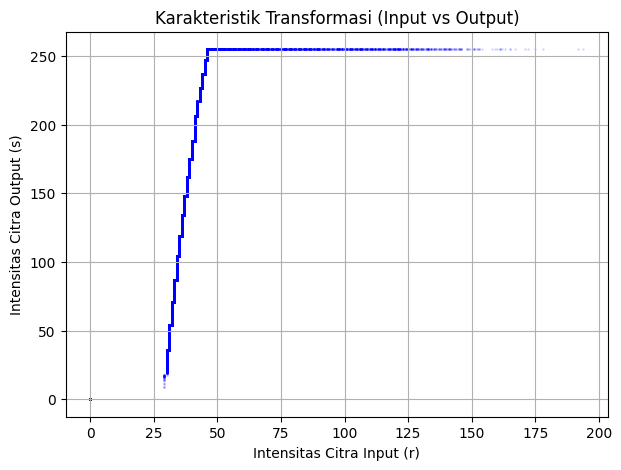

In [27]:
img_in = cv2.imread('/content/citra_input.png')[::10, ::10, 0]
img_out = cv2.imread('/content/contoh_output.png')[::10, ::10, 0]

plt.figure(figsize=(7, 5))
plt.scatter(img_in.flatten(), img_out.flatten(), alpha=0.1, s=1, color='blue')
plt.title("Karakteristik Transformasi (Input vs Output)")
plt.xlabel("Intensitas Citra Input (r)")
plt.ylabel("Intensitas Citra Output (s)")
plt.grid(True)
plt.show()

### Menggunakan Piecewise Linear Transformation untuk Skala 8-bit

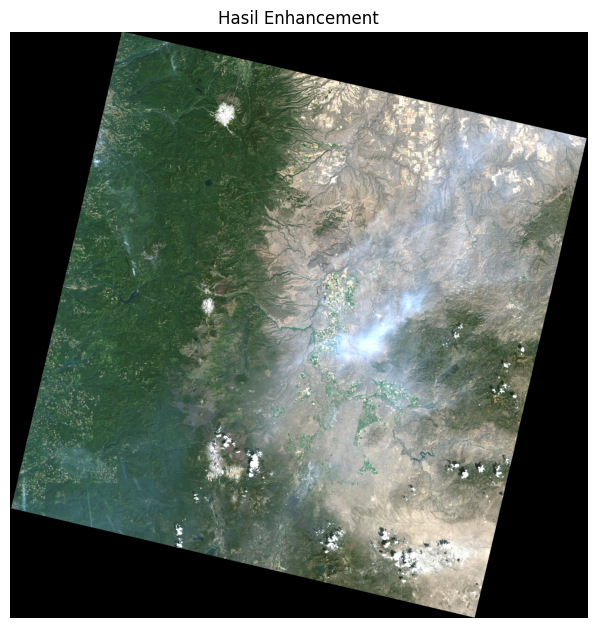

True

In [28]:
img = cv2.imread('/content/citra_input.png')

channel_params = [
    (28, 45),
    (22, 44),
    (20, 47)
]

output_channels = []

for ch_idx, (r1, r2) in enumerate(channel_params):
    c = img[:, :, ch_idx].astype(np.float32)

    stretched = (c - r1) * (255.0 / (r2 - r1))
    stretched = np.clip(stretched, 0, 255)

    stretched[c == 0] = 0

    output_channels.append(stretched.astype(np.uint8))

img_enhanced = cv2.merge(output_channels)

plt.figure(figsize=(12, 12))

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img_enhanced, cv2.COLOR_BGR2RGB))
plt.title("Hasil Enhancement")
plt.axis('off')

plt.tight_layout()
plt.show()

cv2.imwrite('hasil_enhancement_8_bit.png', img_enhanced)

(np.float64(-0.5), np.float64(7710.5), np.float64(7830.5), np.float64(-0.5))

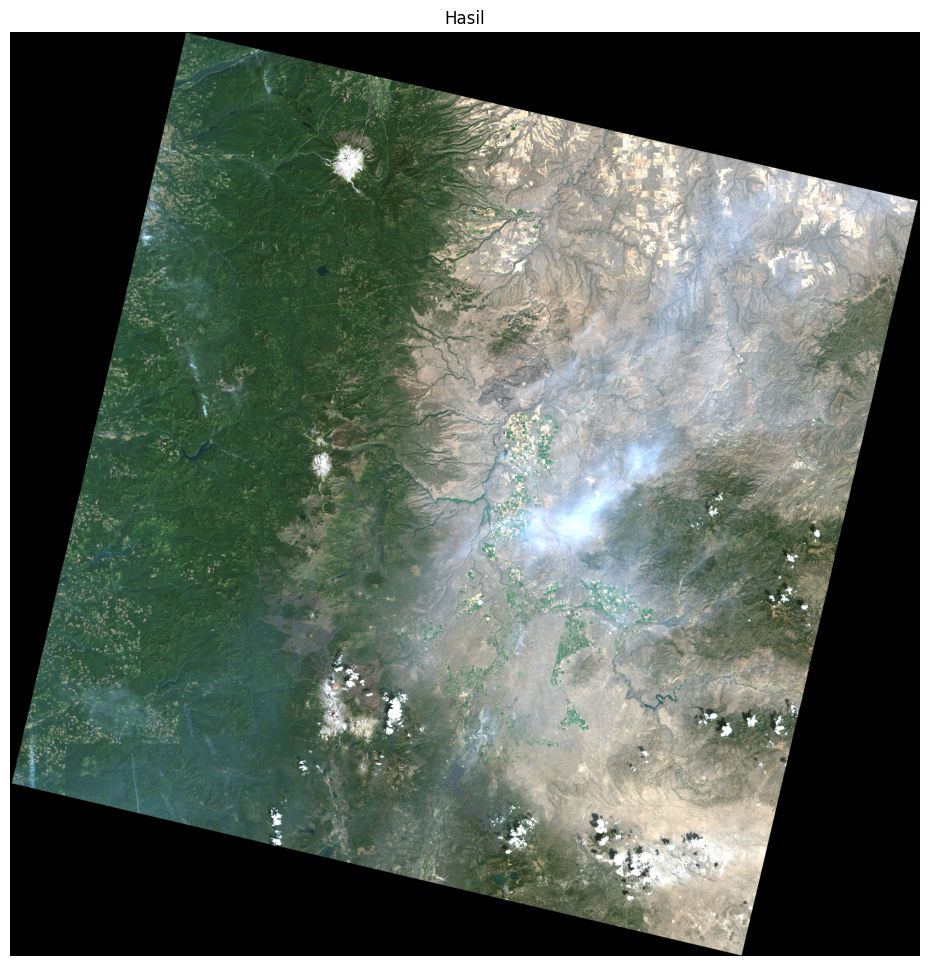

In [29]:
plt.figure(figsize=(12, 12))
plt.imshow(cv2.cvtColor(img_enhanced, cv2.COLOR_BGR2RGB))
plt.title("Hasil")
plt.axis('off')

### Enhancement Image dengan bit asli (16-bit)

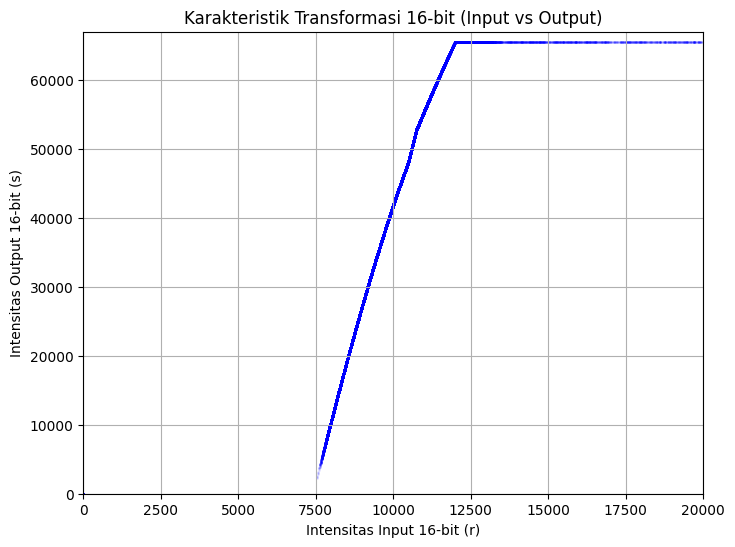

In [30]:
img_in = cv2.imread('/content/citra_input.png', cv2.IMREAD_UNCHANGED)[::10, ::10, 0]
img_out = cv2.imread('/content/contoh_output.png', cv2.IMREAD_UNCHANGED)[::10, ::10, 0]

plt.figure(figsize=(8, 6))
plt.scatter(img_in.flatten(), img_out.flatten(), alpha=0.1, s=1, color='blue')
plt.title('Karakteristik Transformasi 16-bit (Input vs Output)')
plt.xlabel('Intensitas Input 16-bit (r)')
plt.ylabel('Intensitas Output 16-bit (s)')
plt.xlim([0, 20000])
plt.ylim([0, 67000])
plt.grid(True)
plt.show()


### Menggunakan Piecewise Linear Transformation untuk Skala 16-bit

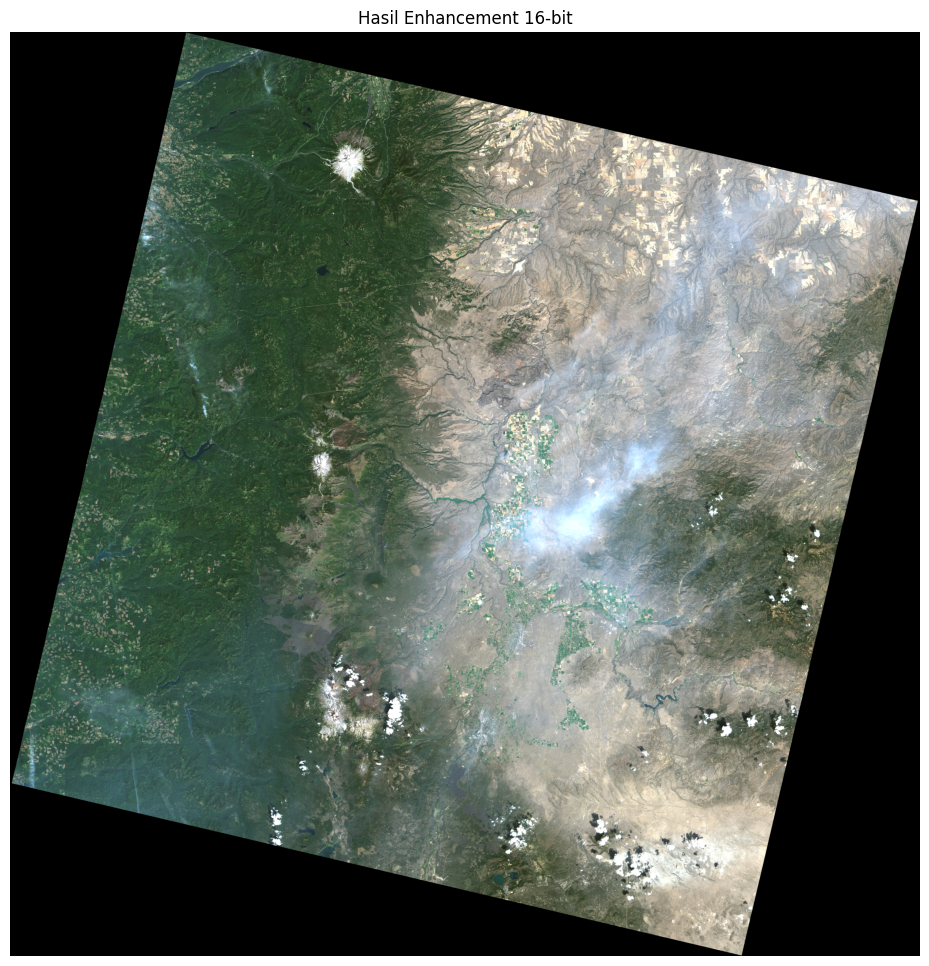

In [31]:
img = cv2.imread('citra_input.png', cv2.IMREAD_UNCHANGED)

channel_params = [
    (7298, 11712),
    (5878, 11412),
    (5238, 12250)
]

output_channels = []

for ch_idx, (r1, r2) in enumerate(channel_params):
    c = img[:, :, ch_idx].astype(np.float32)

    stretched = (c - r1) * (65535.0 / (r2 - r1))
    stretched = np.clip(stretched, 0, 65535)

    stretched[c == 0] = 0

    output_channels.append(stretched.astype(np.uint16))

img_enhanced = cv2.merge(output_channels)

cv2.imwrite('hasil_enhancement_16_bit.png', img_enhanced, [cv2.IMWRITE_PNG_COMPRESSION, 1])

preview = cv2.cvtColor((img_enhanced // 256).astype(np.uint8), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(12, 12))
plt.imshow(preview)
plt.title('Hasil Enhancement 16-bit')
plt.axis('off')
plt.show()


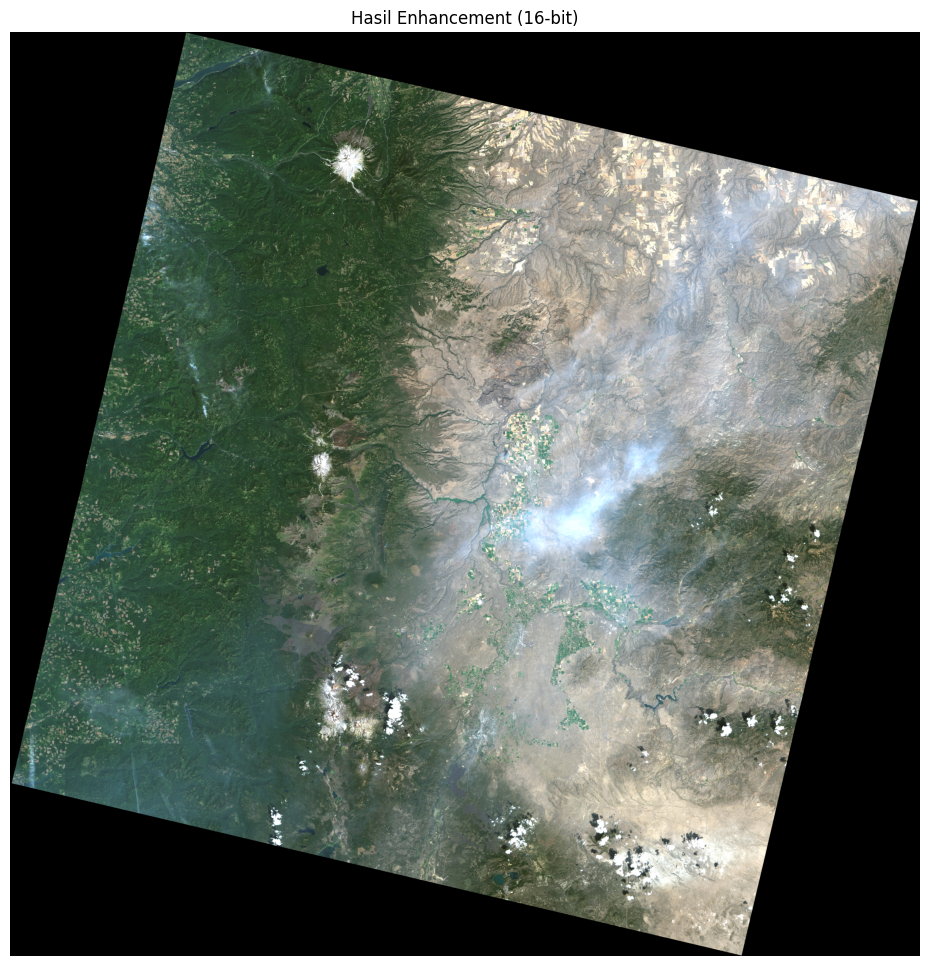

In [32]:
plt.figure(figsize=(12, 12))
preview = cv2.cvtColor((img_enhanced // 256).astype(np.uint8), cv2.COLOR_BGR2RGB)
plt.imshow(preview)
plt.title("Hasil Enhancement (16-bit)")
plt.axis('off')
plt.show()
